# Study 20 — Reviewer diagnostics (consolidated)

Light diagnostic cells for the remaining reviewer points, all reusing the study4/study12 Nordic pipeline:

- **A** residual Q-Q per state (R2 §2.3): is the Gaussian emission adequate?
- **B** conditional-independence check (R2 §2.3): correlations among wind, BLH, temperature.
- **C** test-period composition per partition (R2 §2.6): interleaved vs chronological.
- **D** per-update latency (R2 §4): milliseconds per filter update.
- **E** Figure 5 overlay (R2 §3.4): GBM reliability curve beside the twin's.
- **F** outage gap pool / 644-day gap (R2 §2.6): confirm extreme gaps are in the pool.

cwd=`notebooks/`. Outputs -> `../outputs/study20_diagnostics/`.


## Load + twin (with MAP states) + metrics


In [1]:
import numpy as np, pandas as pd, math, time, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
np.random.seed(0)
OUT=Path("../outputs/study20_diagnostics"); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":200,"font.size":11,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
STEP=6; H=4; TAU=15.0
pm=pd.read_csv("../data/openaq_regional/regional_pm25.csv"); pm["datetime"]=pd.to_datetime(pm["datetime"],utc=True)
pm["name"]=pm.station.str.split("::").str[1]; pm=pm.dropna(subset=["value"]); pm=pm[(pm.value>=0)&(pm.value<1500)]
met=pd.read_csv("../data/era5/era5_regional.csv",usecols=["datetime","station","wind_speed","blh","t2m"])
met["datetime"]=pd.to_datetime(met["datetime"],utc=True); met=met.rename(columns={"station":"name"})
yrs=pm.groupby("station")["datetime"].agg(lambda s:(s.max()-s.min()).days/365.25); pm=pm[pm.station.isin(yrs[yrs>=2].index)].copy()

K=5; _LEVL=[i/(K-1) for i in range(K)]; _SDL=[1.0+0.5*l for l in _LEVL]; _LOGC=0.5*math.log(2*math.pi); _LGCONST=[-_LOGC-math.log(sd) for sd in _SDL]
def _lgv(z): return [_LGCONST[k]-0.5*((z-2.0*_LEVL[k])/_SDL[k])**2 for k in range(K)]
WPM,WW,WB,WT=1.0,0.5,0.5,0.4
def twin(zpm,zw,zb,zt,return_states=False):
    logb=[-3*k for k in range(K)]; m=max(logb); ss=sum(math.exp(x-m) for x in logb); logb=[x-m-math.log(ss) for x in logb]
    risk=np.empty(len(zpm)); states=np.empty(len(zpm),int)
    for t in range(len(zpm)):
        mb=max(logb); b=[math.exp(x-mb) for x in logb]; sb=sum(b); b=[x/sb for x in b]
        el=sum(b[k]*_LEVL[k] for k in range(K)); up=0.25; pdn=0.05 if el>0.4 else 0.15; bp=[0.0]*K
        for k in range(K):
            u=up if k<K-1 else 0.0; d=pdn if k>0 else 0.0; bp[k]+=b[k]*(1-u-d)
            if k<K-1: bp[k+1]+=b[k]*u
            if k>0: bp[k-1]+=b[k]*d
        logbp=[math.log(x+1e-12) for x in bp]
        for zv,w,inv in [(zpm,WPM,1),(zw,WW,-1),(zb,WB,-1),(zt,WT,-1)]:
            if not math.isnan(zv[t]):
                lv=_lgv(inv*zv[t]); logbp=[logbp[k]+w*lv[k] for k in range(K)]
        m2=max(logbp); s2=math.log(sum(math.exp(x-m2) for x in logbp)); logb=[x-m2-s2 for x in logbp]
        eb=[math.exp(x) for x in logb]; risk[t]=sum(eb[k]*_LEVL[k] for k in range(K)); states[t]=int(np.argmax(eb))
    return (risk,states) if return_states else risk
def auc(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);pos,neg=(y==1),(y==0)
    if pos.sum()==0 or neg.sum()==0:return np.nan
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    u,inv,c=np.unique(s,return_inverse=True,return_counts=True);sm=np.zeros(len(c));np.add.at(sm,inv,r);r=(sm/c)[inv]
    return float((r[pos].sum()-pos.sum()*(pos.sum()+1)/2)/(pos.sum()*neg.sum()))
def brier(p,y): return float(np.mean((np.asarray(p,float)-np.asarray(y,float))**2))
def ece(p,y,nb=10):
    p=np.asarray(p,float); y=np.asarray(y,float); ed=np.linspace(0,1,nb+1); e=0.0
    for i in range(nb):
        mk=(p>=ed[i])&(p<ed[i+1] if i<nb-1 else p<=ed[i+1])
        if mk.sum(): e+=mk.mean()*abs(y[mk].mean()-p[mk].mean())
    return float(e)
def sig(z):return 1/(1+np.exp(-np.clip(z,-30,30)))
def fitlog(X,y,ep=1500,lr=.25,l2=1.):
    X=np.asarray(X,float);mu=X.mean(0);sd=X.std(0)+1e-9;Xb=np.hstack([np.ones((len(X),1)),(X-mu)/sd]);w=np.zeros(Xb.shape[1])
    for _ in range(ep): p=sig(Xb@w);g=Xb.T@(p-y)/len(y);g[1:]+=l2/len(y)*w[1:];w-=lr*g
    return (w,mu,sd)
def predlog(m,X): w,mu,sd=m; return sig(np.hstack([np.ones((len(X),1)),(np.asarray(X,float)-mu)/sd])@w)
def platt_fit(x,y,ep=3000,lr=.3):
    x=np.asarray(x,float);mu,sd=x.mean(),x.std()+1e-9;xs=(x-mu)/sd;w=0.;bi=0.
    for _ in range(ep): p=1/(1+np.exp(-(w*xs+bi)));w-=lr*np.mean((p-y)*xs);bi-=lr*np.mean(p-y)
    return lambda z:1/(1+np.exp(-(w*((np.asarray(z,float)-mu)/sd)+bi)))


/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## Build ST + onset table (retain per-station arrays and timestamps)


In [2]:
FEATS=["zpm","zpm_l1","zpm_l2","zpm_tr","zwind","zblh","ztemp","hour_sin","hour_cos","doy_sin","doy_cos"]
ST={}; rows=[]
for st,g in pm.groupby("station"):
    name=g["name"].iloc[0]
    s=g.set_index("datetime").value.resample(f"{STEP}h").mean()
    mg=met[met.name==name].set_index("datetime")[["wind_speed","blh","t2m"]].resample(f"{STEP}h").mean()
    idx=s.index; A=pd.DataFrame({"pm":s}).join(mg).reindex(idx); tm=(idx.month%2==0)
    def z(col,log=False):
        v=np.log1p(np.clip(A[col].to_numpy(),0,None)) if log else A[col].to_numpy()
        mu,sd=np.nanmean(v[tm]),np.nanstd(v[tm])+1e-9; return (v-mu)/sd
    zpm=z("pm",log=True); zw=z("wind_speed"); zb=z("blh"); zt=z("t2m")
    risk,states=twin(zpm,zw,zb,zt,return_states=True)
    v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); g2=lambda a:(a if not np.isnan(a) else 0.0)
    ST[st]=dict(zpm=zpm,zw=zw,zb=zb,zt=zt,v=v,tm=tm,states=states,risk=risk,idx=idx)
    for t in range(2,len(v)-H):
        if np.isnan(v[t]) or v[t]>=TAU: continue
        fut=v[t+1:t+1+H]
        if np.all(np.isnan(fut)): continue
        rows.append(dict(dt=idx[t],month=idx[t].month,split=("train" if tm[t] else "test"),label=int(np.nanmax(fut)>=TAU),
            zpm=g2(zpm[t]),zpm_l1=g2(zpm[t-1]),zpm_l2=g2(zpm[t-2]),zpm_tr=g2(zpm[t]-zpm[t-2]),zwind=g2(zw[t]),zblh=g2(zb[t]),ztemp=g2(zt[t]),
            hour_sin=math.sin(2*math.pi*hr[t]/24),hour_cos=math.cos(2*math.pi*hr[t]/24),doy_sin=math.sin(2*math.pi*doy[t]/365),doy_cos=math.cos(2*math.pi*doy[t]/365),
            risk=risk[t]))
S=pd.DataFrame(rows); tr,te=S[S.split=="train"],S[S.split=="test"]
print("onset samples",len(S),"| prevalence %.3f"%S.label.mean())


/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_87044/2581046440.py:13: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); g2=lambda a:(a if not np.isnan(a) else 0.0)
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_87044/2581046440.py:13: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); g2=lambda a:(a if not np.isnan(a) else 0.0)
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_87044/2581046440.py:13: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); g2=lambda a:(a if not np.is

onset samples 92890 | prevalence 0.073


## A. Residual Q-Q per state (Gaussian emission adequacy)


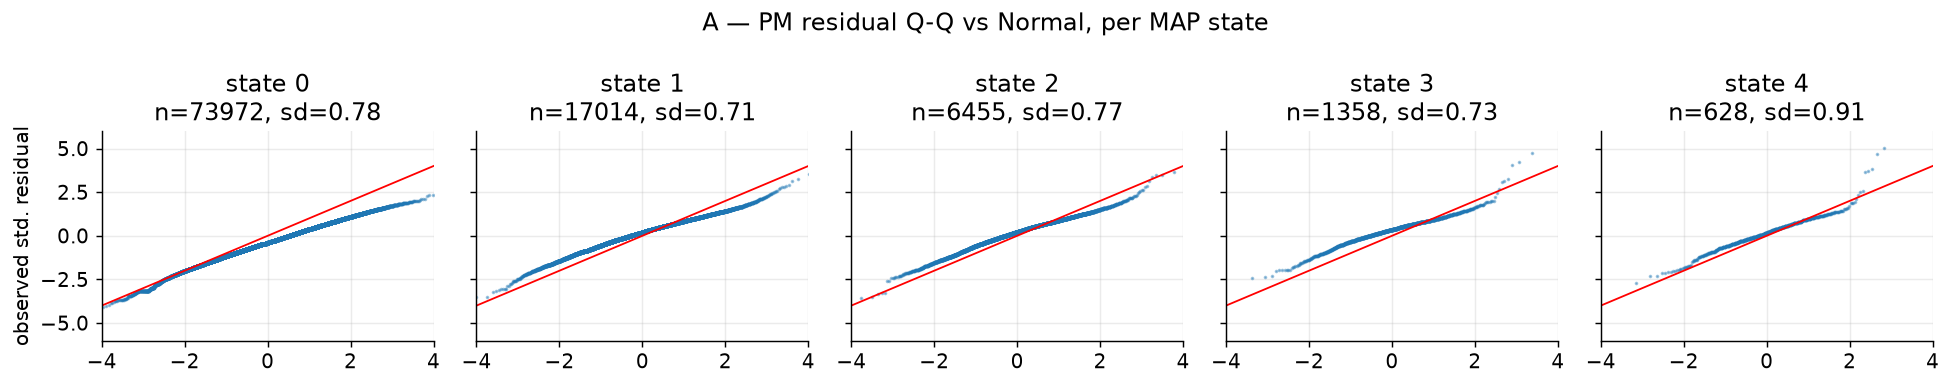

 state     n   mean   std  excess_kurtosis
     0 73972 -0.405 0.778            0.229
     1 17014  0.151 0.713            0.581
     2  6455  0.155 0.765            0.664
     3  1358  0.303 0.730            2.902
     4   628  0.167 0.913            5.468
Read: std near 1 and low excess kurtosis => Gaussian adequate; heavy tails (high kurtosis) in upper states flag the concern.


In [3]:
# standardized PM residual for each observation under its MAP state k: (zpm - 2*LEV[k]) / SD[k]
res_by_state={k:[] for k in range(K)}
for st,d in ST.items():
    zpm=d["zpm"]; stt=d["states"]
    for t in range(len(zpm)):
        if np.isnan(zpm[t]): continue
        k=int(stt[t]); res_by_state[k].append((zpm[t]-2.0*_LEVL[k])/_SDL[k])
def qq(resid):
    r=np.sort(np.asarray(resid,float)); n=len(r)
    q=(np.arange(1,n+1)-0.5)/n
    theo=np.sqrt(2)*np.vectorize(lambda p: _erfinv(2*p-1))(q)
    return theo,r
def _erfinv(x):  # Winitzki approximation (no scipy dependency)
    a=0.147; ln=np.log(1-x*x); t=2/(math.pi*a)+ln/2
    return np.sign(x)*np.sqrt(np.sqrt(t*t-ln/a)-t)
fig,ax=plt.subplots(1,K,figsize=(3*K,3),sharex=True,sharey=True)
summ=[]
for k in range(K):
    r=np.array(res_by_state[k],float)
    if len(r)<20: ax[k].set_title(f"state {k}\nn={len(r)}"); continue
    theo,obs=qq(r); ax[k].plot(theo,obs,".",ms=2,alpha=.4); lim=[-4,4]; ax[k].plot(lim,lim,"r-",lw=1)
    ax[k].set_title(f"state {k}\nn={len(r)}, sd={r.std():.2f}"); ax[k].set_xlim(lim); ax[k].set_ylim(-6,6)
    summ.append(dict(state=k,n=len(r),mean=float(r.mean()),std=float(r.std()),
                     excess_kurtosis=float(((r-r.mean())**4).mean()/(r.std()**4)-3)))
ax[0].set_ylabel("observed std. residual"); fig.suptitle("A — PM residual Q-Q vs Normal, per MAP state")
plt.tight_layout(); plt.savefig(OUT/"s20_A_qq_residuals.png",bbox_inches="tight"); plt.show()
qdf=pd.DataFrame(summ); print(qdf.round(3).to_string(index=False)); qdf.to_csv(OUT/"s20_A_residual_summary.csv",index=False)
print("Read: std near 1 and low excess kurtosis => Gaussian adequate; heavy tails (high kurtosis) in upper states flag the concern.")



## B. Conditional-independence check (met channel correlations)


In [4]:
cols=["zwind","zblh","ztemp"]; Cm=S[cols].corr()
print("Pearson correlations among meteorological channels (test+train onset points):")
print(Cm.round(3).to_string()); Cm.to_csv(OUT/"s20_B_met_correlations.csv")
print("\nRead: large |r| would undercut the conditional-independence (naive-fusion) assumption; small |r| supports it.")


Pearson correlations among meteorological channels (test+train onset points):
       zwind   zblh  ztemp
zwind   1.00  0.620 -0.060
zblh    0.62  1.000  0.268
ztemp  -0.06  0.268  1.000

Read: large |r| would undercut the conditional-independence (naive-fusion) assumption; small |r| supports it.


## C. Test-period composition: interleaved vs chronological


In [5]:
def compo(mask,name):
    sub=S[mask]
    seas=sub.month.value_counts().sort_index()
    return dict(scheme=name,n_test=len(sub),n_onset=int(sub.label.sum()),base_rate=float(sub.label.mean()),
               winter_frac=float(sub.month.isin([12,1,2]).mean()))
inter_mask=S.split=="test"                               # odd months
cut=S.dt.quantile(0.7); chrono_mask=S.dt>cut             # last 30% chronologically
comp=pd.DataFrame([compo(inter_mask,"interleaved (odd months)"),compo(chrono_mask,"chronological (last 30%)")]).set_index("scheme")
print(comp.round(3).to_string()); comp.to_csv(OUT/"s20_C_partition_composition.csv")
print("\nRead: if the chronological test set is more winter-heavy or higher base rate, its higher AUROC reflects test-set difficulty,")
print("not partition design, which is the reviewer's §2.6 concern.")


                          n_test  n_onset  base_rate  winter_frac
scheme                                                           
interleaved (odd months)   48209     3364      0.070        0.189
chronological (last 30%)   27853     1974      0.071        0.255

Read: if the chronological test set is more winter-heavy or higher base rate, its higher AUROC reflects test-set difficulty,
not partition design, which is the reviewer's §2.6 concern.


## D. Per-update latency (ms per filter update)


In [6]:
# time the filter over several stations; report ms per station-step (pure-python upper bound)
times=[]
for st,d in list(ST.items())[:5]:
    n=len(d["zpm"]); t0=time.perf_counter(); _=twin(d["zpm"],d["zw"],d["zb"],d["zt"]); dt=time.perf_counter()-t0
    times.append(dt/n*1000.0)
mean_ms=float(np.mean(times))
print(f"mean latency per filter update: {mean_ms:.4f} ms/step  (pure-Python reference; a vectorized/compiled impl is faster)")
pd.DataFrame([{"ms_per_update":mean_ms,"n_stations_timed":5,"impl":"pure-python"}]).to_csv(OUT/"s20_D_latency.csv",index=False)


mean latency per filter update: 0.0106 ms/step  (pure-Python reference; a vectorized/compiled impl is faster)


## E. Figure 5 overlay: GBM reliability beside the twin


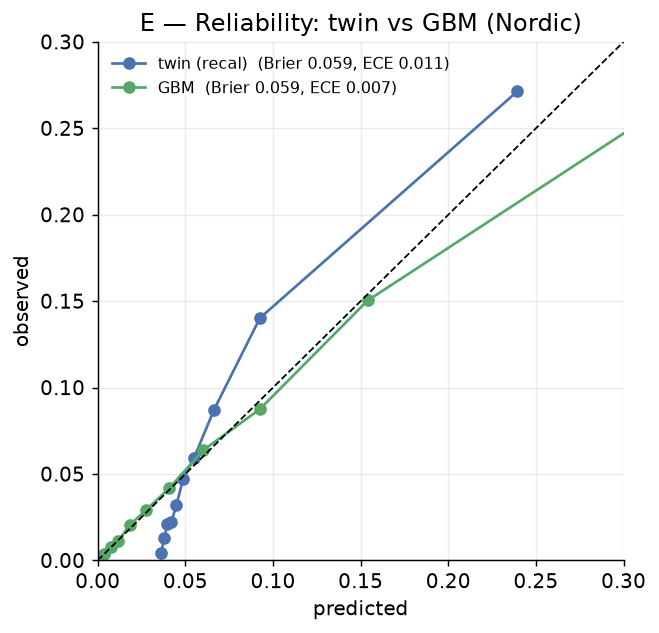

In [7]:
ytr,yte=tr.label.values,te.label.values
gbm=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,max_depth=4,l2_regularization=1.0,random_state=0).fit(tr[FEATS].values,ytr)
p_gbm=gbm.predict_proba(te[FEATS].values)[:,1]
p_twin=platt_fit(tr.risk.values,ytr)(te.risk.values)
def rel(p,yy,nb=10):
    b=pd.qcut(p,nb,duplicates="drop"); grp=pd.DataFrame({"p":p,"y":yy}).groupby(b,observed=True); return grp.p.mean().values,grp.y.mean().values
fig,ax=plt.subplots(figsize=(5.2,5)); mx=0.3
for p,lab,c in [(p_twin,"twin (recal)","#4C72B0"),(p_gbm,"GBM","#55A868")]:
    xp,yp=rel(p,yte); ax.plot(xp,yp,"-o",label=f"{lab}  (Brier {brier(p,yte):.3f}, ECE {ece(p,yte):.3f})",color=c)
ax.plot([0,mx],[0,mx],"k--",lw=1); ax.set_xlim(0,mx); ax.set_ylim(0,mx)
ax.set_xlabel("predicted"); ax.set_ylabel("observed"); ax.set_title("E — Reliability: twin vs GBM (Nordic)"); ax.legend(frameon=False,fontsize=9)
plt.tight_layout(); plt.savefig(OUT/"s20_E_reliability_twin_vs_gbm.png",bbox_inches="tight"); plt.show()


## F. Outage gap pool / 644-day gap confirmation


In [8]:
# rebuild the observed contiguous gap distribution exactly as study12 does, and report extremes
gaps=[]
for st,d in ST.items():
    isnan=np.isnan(d["zpm"]); n=len(isnan); i=0
    while i<n:
        if isnan[i]:
            j=i
            while j<n and isnan[j]: j+=1
            gaps.append(j-i); i=j
        else: i+=1
gaps=np.array(gaps)
mx_steps=int(gaps.max()); mx_days=mx_steps*STEP/24
print(f"observed gap runs: n={len(gaps)} | median {np.median(gaps):.0f} steps | p99 {np.percentile(gaps,99):.0f} | max {mx_steps} steps = {mx_days:.0f} days")
print("block_mask samples L=choice(gaps) then clamps L=min(L, series_len), so the maximum gap IS in the pool;")
print("when drawn it is capped at the station's length. Extreme gaps are therefore represented in the outage simulation.")
pd.DataFrame([{"n_gaps":len(gaps),"median_steps":float(np.median(gaps)),"p99_steps":float(np.percentile(gaps,99)),
              "max_steps":mx_steps,"max_days":mx_days,"step_hours":STEP}]).to_csv(OUT/"s20_F_gap_pool.csv",index=False)
print("saved all diagnostics to",OUT)


observed gap runs: n=4025 | median 2 steps | p99 121 | max 2577 steps = 644 days
block_mask samples L=choice(gaps) then clamps L=min(L, series_len), so the maximum gap IS in the pool;
when drawn it is capped at the station's length. Extreme gaps are therefore represented in the outage simulation.
saved all diagnostics to ../outputs/study20_diagnostics


## Reading this for the reply
- A: cite the per-state residual table; if upper states show heavy tails, acknowledge and note the increasing-variance emission partly addresses it, offering a mixture/heavy-tailed emission as future work.
- B: report the met-channel correlations; frame conditional independence as an approximation with the measured correlations stated.
- C: use the composition table to replace the 'conservatism' assertion with the actual test-set difficulty comparison.
- D: quote the per-update latency as evidence of real-time feasibility.
- E: this is the Figure 5 overlay the reviewer asked for.
- F: state that extreme gaps (max ~ the reported days) are included in the block-outage pool, clamped to series length.
